## 1.1 — Installation of Required Libraries
Install the essential Python libraries for AI-based image compression, image processing, visualization, and performance evaluation.

In [ ]:
%pip install --no-cache-dir "compressai==1.2.8"
%pip install pillow pandas matplotlib scikit-image tqdm

  Using cached numpy-2.5.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
compressai 1.2.8 requires numpy<2.0,>=1.21.0, but you have numpy 2.5.4 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.5.4 which is incompatible.


## 1.2 — Library Imports and Environment Verification
Import the required libraries and verify the Python environment, PyTorch, NumPy, and CompressAI versions to ensure compatibility and reproducibility.

In [ ]:
# ============================================================
# SECTION 1: ENVIRONMENT SETUP
# Project 30: Classical vs. Learned Image Compression
# ============================================================

import sys
import random
import time
import platform

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

import compressai

from PIL import Image

from torchvision.transforms.functional import (
    to_tensor,
    to_pil_image
)

from skimage.metrics import peak_signal_noise_ratio

print("=" * 55)
print("ENVIRONMENT INFORMATION")
print("=" * 55)

print("Python:", sys.version.split()[0])
print("Operating System:", platform.system())
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("CompressAI:", compressai.__version__)

print("=" * 55)

ENVIRONMENT INFORMATION
Python: 3.12.13
Operating System: Linux
PyTorch: 2.11.0+cpu
NumPy: 2.5.4
CompressAI: 1.2.8


## 1.3 — Experiment Configuration and Reproducibility
Define project directories, dataset paths, output locations, random seeds, computing device (CPU/GPU), and compression parameters.

In [ ]:
# ============================================================
# EXPERIMENT CONFIGURATION
# ============================================================

# Project directory
ROOT = Path("/content/DIP_Project")

# Dataset directories
DATASETS = {
    "Kodak": ROOT / "datasets/kodak",
    "Tecnick": ROOT / "datasets/tecnick",
    "CLIC": ROOT / "datasets/clic_validation"
}

# Output directories
RESULTS_DIR = ROOT / "results"
REPORTS_DIR = ROOT / "reports"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device selection
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Model configuration
MODEL_QUALITY = 3

# Image padding
PADDING_MULTIPLE = 64

print("\nExperiment Configuration")
print("Root:", ROOT)
print("Quality:", MODEL_QUALITY)
print("Random Seed:", SEED)
print("Padding Multiple:", PADDING_MULTIPLE)

Selected device: cpu

Experiment Configuration
Root: /content/DIP_Project
Quality: 3
Random Seed: 42
Padding Multiple: 64


## 1.4 — Automatic Download and Selection of Sample Images from Benchmark Datasets

This section automatically retrieves one sample image from each of the three benchmark datasets: **Kodak, Tecnick, and CLIC**.

The selected images will be used to validate the AI-based compression pipeline before conducting full-dataset experiments.

### Objectives
- Download one image from each benchmark dataset.
- Reuse existing images to avoid unnecessary downloads.
- Organize the selected images into their respective dataset directories.
- Convert images to RGB format for consistent processing.
- Record image dimensions and filenames for reproducibility.
- Prepare the images for compression and reconstruction experiments.

In [ ]:
%pip install -q huggingface_hub

In [10]:
# ============================================================
# 1.4 — DOWNLOAD ONE IMAGE FROM EACH DATASET
# ============================================================

from pathlib import Path
from huggingface_hub import list_repo_files, hf_hub_download
from PIL import Image
import matplotlib.pyplot as plt
import shutil

ROOT = Path("/content/DIP_Project")

REPO_ID = "SCU-VIP-Lab/compression-eval-datasets"

DATASETS = {
    "Kodak": {
        "source": "kodak/",
        "destination": ROOT / "datasets/kodak"
    },
    "Tecnick": {
        "source": "tecnick/",
        "destination": ROOT / "datasets/tecnick"
    },
    "CLIC": {
        "source": "clic2021_valid/",
        "destination": ROOT / "datasets/clic_validation"
    }
}

# Get repository file listing (without downloading the dataset)
repo_files = list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

sample_images = {}
sample_paths = {}

extensions = (".png", ".jpg", ".jpeg")

for dataset_name, config in DATASETS.items():

    folder = config["destination"]
    folder.mkdir(parents=True, exist_ok=True)

    # Check for existing images
    existing = sorted([
        p for p in folder.rglob("*")
        if p.suffix.lower() in extensions
    ])

    if existing:
        image_path = existing[0]
        print(f"{dataset_name}: Using existing image")

    else:
        # Find available images in repository
        candidates = sorted([
            f for f in repo_files
            if f.startswith(config["source"])
            and f.lower().endswith(extensions)
        ])

        if not candidates:
            print(f"{dataset_name}: No images found")
            continue

        # Download only the first image
        selected_file = candidates[0]

        downloaded_path = hf_hub_download(
            repo_id=REPO_ID,
            filename=selected_file,
            repo_type="dataset"
        )

        image_path = folder / Path(selected_file).name

        shutil.copy2(downloaded_path, image_path)

        print(f"{dataset_name}: Download completed")

    # Load RGB image
    with Image.open(image_path) as img:
        image = img.convert("RGB")

    sample_images[dataset_name] = image
    sample_paths[dataset_name] = image_path

    print("Image:", image_path.name)
    print("Resolution:", image.size)
    print("-" * 50)

kodak/kodim01.png: reconstructing file:   0%|          |  0.00B /  737kB            

kodak/kodim01.png: downloading bytes:           |  0.00B            

Kodak: Download completed
Image: kodim01.png
Resolution: (768, 512)
--------------------------------------------------


tecnick/img_1200x1200_3x8bit_T01R01_RGB_(…): reconstructing file:   0%|          |  0.00B / 2.12MB            

tecnick/img_1200x1200_3x8bit_T01R01_RGB_(…): downloading bytes:           |  0.00B            

Tecnick: Download completed
Image: img_1200x1200_3x8bit_T01R01_RGB_almonds.png
Resolution: (1200, 1200)
--------------------------------------------------


clic2021_valid/alberto-montalesi-176097.(…): reconstructing file:   0%|          |  0.00B / 4.25MB            

clic2021_valid/alberto-montalesi-176097.(…): downloading bytes:           |  0.00B            

CLIC: Download completed
Image: alberto-montalesi-176097.png
Resolution: (2048, 1363)
--------------------------------------------------


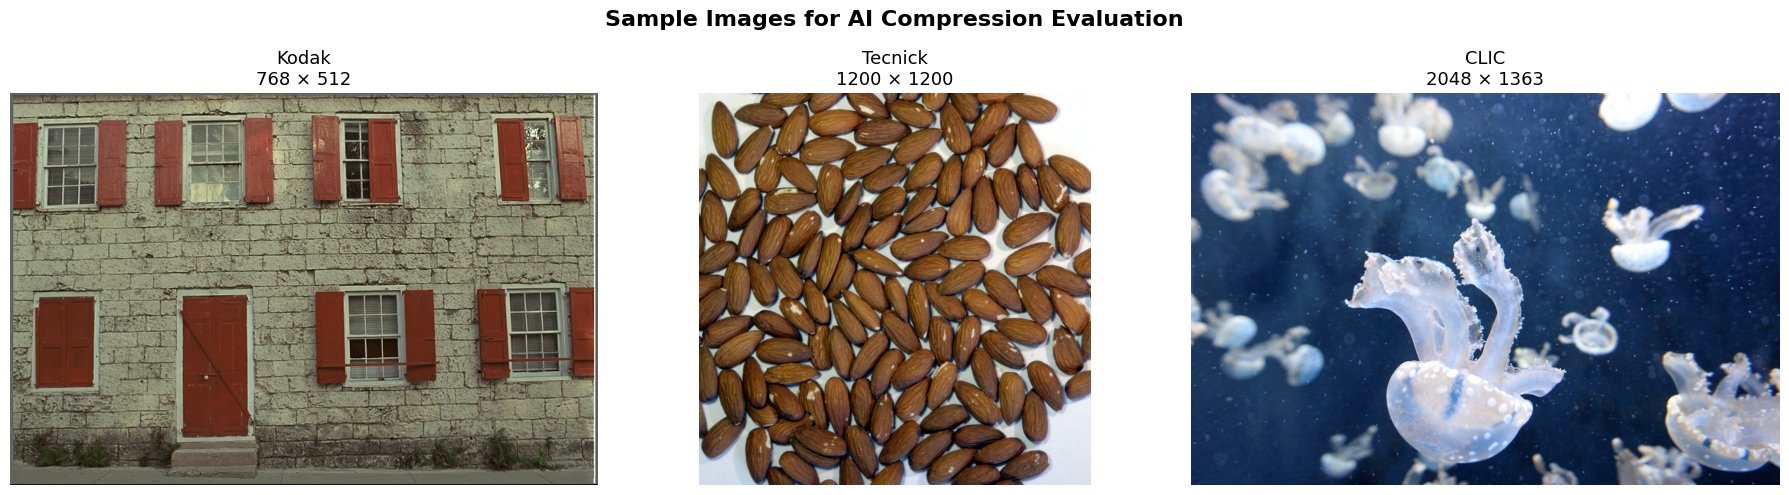

In [ ]:
# ============================================================
# 1.5 — VISUALIZE SAMPLE IMAGES
# ============================================================

fig, axes = plt.subplots(
    1,
    len(sample_images),
    figsize=(18, 5),
    squeeze=False
)

for ax, (name, image) in zip(
    axes[0],
    sample_images.items()
):

    ax.imshow(image)

    ax.set_title(
        f"{name}\n"
        f"{image.width} × {image.height}",
        fontsize=13
    )

    ax.axis("off")

plt.suptitle(
    "Sample Images for AI Compression Evaluation",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

results = []

for name, image in sample_images.items():

    results.append({
        "Dataset": name,
        "Image": sample_paths[name].name,
        "Width": image.width,
        "Height": image.height,
        "Color Mode": image.mode
    })

df = pd.DataFrame(results)

display(df)

assert len(sample_images) == 3, (
    "Expected one image from each of the three datasets."
)

print("All three datasets are ready for AI compression!")

,Dataset,Image,Width,Height,Color Mode
0,Kodak,kodim01.png,768,512,RGB
1,Tecnick,img_1200x1200_3x8bit_T01R01_RGB_almonds.png,1200,1200,RGB
2,CLIC,alberto-montalesi-176097.png,2048,1363,RGB


All three datasets are ready for AI compression!


## 1.5 — Environment Setup Summary

This section establishes a reproducible experimental environment for evaluating pretrained AI-based image compression models.

The setup includes:
- Installation and verification of required libraries.
- Automatic CPU/GPU device selection.
- Configuration of dataset and output directories.
- Initialization of random seeds for reproducibility.
- Verification of the Kodak, Tecnick, and CLIC datasets.

The configured environment will be used consistently throughout the compression experiments to support fair and reproducible comparisons.

## 2.1 — Introduction to Pretrained Learned Image Compression Models

Learned image compression uses neural networks to transform images into
compact latent representations that can be efficiently encoded and
transmitted.

Unlike traditional compression methods such as JPEG and JPEG2000,
learned compression models optimize neural-network transforms and
entropy models to achieve a favorable trade-off between bitrate
and reconstruction quality.

This project evaluates three pretrained compression architectures:

1. **Factorized Prior (Ballé et al., 2018):**
   Uses a learned analysis transform, quantization, and a factorized
   entropy model to compress images.

2. **Scale Hyperprior (Ballé et al., 2018):**
   Extends learned compression by introducing a hyperprior that
   estimates the probability distribution of latent representations,
   improving entropy coding efficiency.

3. **Cheng2020 Anchor (Cheng et al., 2020):**
   Uses residual and attention-based neural-network components
   with a more advanced entropy model to improve rate–distortion
   performance.

### Objective

The objective is to initialize these pretrained architectures using
CompressAI and prepare them for consistent compression experiments
on Kodak, Tecnick, and CLIC images.

All models will operate in evaluation mode using pretrained weights,
without additional training.

## 2.2 — Import Pretrained Compression Architectures

This subsection imports the pretrained neural image compression
architectures provided by CompressAI.

The models are loaded from the CompressAI model zoo, which provides
pretrained weights for different compression quality levels.

The imported architectures will be used for inference only.

In [ ]:
# ============================================================
# 2.2 — IMPORT PRETRAINED COMPRESSION MODELS
# ============================================================

import torch
import compressai

from compressai.zoo import (
    bmshj2018_factorized,
    bmshj2018_hyperprior,
    cheng2020_anchor
)

print("=" * 55)
print("PRETRAINED AI COMPRESSION MODELS")
print("=" * 55)

print("CompressAI Version:", compressai.__version__)

print("\nAvailable Models:")
print("1. Factorized Prior (Ballé 2018)")
print("2. Scale Hyperprior (Ballé 2018)")
print("3. Cheng2020 Anchor (Cheng 2020)")

print("=" * 55)

PRETRAINED AI COMPRESSION MODELS
CompressAI Version: 1.2.8

Available Models:
1. Factorized Prior (Ballé 2018)
2. Scale Hyperprior (Ballé 2018)
3. Cheng2020 Anchor (Cheng 2020)


## 2.3 — Compression Model Configuration

A centralized configuration is defined for the pretrained compression
architectures.

Each model is associated with its CompressAI implementation and
supported quality levels.

The initial experiment uses quality level 3 to verify that the
compression pipeline operates correctly.

Additional quality levels will be evaluated later to generate
rate–distortion curves.

In [ ]:
# ============================================================
# 2.3 — MODEL CONFIGURATION
# ============================================================

MODEL_CONFIGS = {

    "Factorized Prior": {
        "function": bmshj2018_factorized,
        "qualities": list(range(1, 9)),
        "reference": "Ballé et al. (2018)"
    },

    "Scale Hyperprior": {
        "function": bmshj2018_hyperprior,
        "qualities": list(range(1, 9)),
        "reference": "Ballé et al. (2018)"
    },

    "Cheng2020 Anchor": {
        "function": cheng2020_anchor,
        "qualities": list(range(1, 7)),
        "reference": "Cheng et al. (2020)"
    }
}

INITIAL_QUALITY = 3

print("Configured Compression Models:\n")

for name, config in MODEL_CONFIGS.items():

    print(f"Model: {name}")
    print(f"Reference: {config['reference']}")
    print(f"Supported Qualities: {config['qualities']}")
    print("-" * 50)

Configured Compression Models:

Model: Factorized Prior
Reference: Ballé et al. (2018)
Supported Qualities: [1, 2, 3, 4, 5, 6, 7, 8]
--------------------------------------------------
Model: Scale Hyperprior
Reference: Ballé et al. (2018)
Supported Qualities: [1, 2, 3, 4, 5, 6, 7, 8]
--------------------------------------------------
Model: Cheng2020 Anchor
Reference: Cheng et al. (2020)
Supported Qualities: [1, 2, 3, 4, 5, 6]
--------------------------------------------------


## 2.4 — Reusable Pretrained Model Loading Function

A reusable function is implemented to initialize pretrained image
compression models using the CompressAI model zoo.

The function performs the following operations:

1. Validates the selected model and quality level.
2. Loads the corresponding pretrained model weights.
3. Transfers the model to the available CPU or GPU.
4. Activates evaluation mode to disable training-specific behavior.
5. Initializes the entropy coding tables required for actual
   bitstream compression and decompression.

This approach eliminates duplicated code and ensures that all
compression architectures are initialized consistently.

In [ ]:
# ============================================================
# 2.4 — REUSABLE MODEL LOADER
# ============================================================

def load_compression_model(
    model_name,
    quality=3,
    device=device
):
    """
    Load a pretrained CompressAI compression model.

    Parameters
    ----------
    model_name : str
        Name of the compression architecture.

    quality : int
        Pretrained compression quality level.

    device : torch.device
        CPU or GPU device.

    Returns
    -------
    model : torch.nn.Module
        Initialized pretrained compression model.
    """

    # Validate model name
    if model_name not in MODEL_CONFIGS:
        raise ValueError(
            f"Unknown model: {model_name}"
        )

    config = MODEL_CONFIGS[model_name]

    # Validate quality level
    if quality not in config["qualities"]:
        raise ValueError(
            f"Quality {quality} is not supported "
            f"by {model_name}"
        )

    print("=" * 55)
    print("LOADING COMPRESSION MODEL")
    print("=" * 55)

    print("Model:", model_name)
    print("Quality:", quality)
    print("Device:", device)

    # Load pretrained model
    model = config["function"](
        quality=quality,
        pretrained=True
    )

    # Transfer to device
    model = model.to(device)

    # Enable evaluation mode
    model.eval()

    # Initialize entropy coding tables
    model.update(force=True)

    print("\nModel loaded successfully!")
    print("=" * 55)

    return model

## 2.5 — Factorized Prior Model Initialization

The Factorized Prior model proposed by Ballé et al. is selected
as the initial learned image compression baseline.

The model is initialized with pretrained weights at quality level 3.

This architecture uses learned nonlinear transforms and a factorized
entropy model to encode image information into a compact bitstream.

The initialized model will subsequently be evaluated using sample
images from Kodak, Tecnick, and CLIC.

In [ ]:
# ============================================================
# 2.5 — INITIALIZE FACTORIZED PRIOR MODEL
# ============================================================

model = load_compression_model(
    model_name="Factorized Prior",
    quality=INITIAL_QUALITY,
    device=device
)

print("\nModel is ready for compression!")

LOADING COMPRESSION MODEL
Model: Factorized Prior
Quality: 3
Device: cpu
Downloading: "https://compressai.s3.amazonaws.com/models/v1/bmshj2018-factorized-prior-3-5c6f152b.pth.tar" to /root/.cache/torch/hub/checkpoints/bmshj2018-factorized-prior-3-5c6f152b.pth.tar


100%|██████████| 11.6M/11.6M [00:00<00:00, 33.5MB/s]



Model loaded successfully!

Model is ready for compression!


## 2.6 — Model Architecture and Parameter Analysis

The initialized compression model is inspected to verify its
architecture and calculate the total number of neural-network
parameters.

The analysis includes:

- Model architecture identification.
- Total number of parameters.
- Number of trainable parameters.
- Number of non-trainable parameters.
- Model device and evaluation status.

Parameter counts provide an initial indication of model complexity.

However, parameter count alone does not determine computational
cost, memory consumption, or compression performance.

In [ ]:
# ============================================================
# 2.6 — MODEL PARAMETER ANALYSIS
# ============================================================

def analyze_model(model):

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    non_trainable_params = (
        total_params - trainable_params
    )

    print("=" * 55)
    print("MODEL ARCHITECTURE ANALYSIS")
    print("=" * 55)

    print("Architecture:", model.__class__.__name__)

    print(
        "Total Parameters:",
        f"{total_params:,}"
    )

    print(
        "Trainable Parameters:",
        f"{trainable_params:,}"
    )

    print(
        "Non-Trainable Parameters:",
        f"{non_trainable_params:,}"
    )

    print(
        "Model Device:",
        next(model.parameters()).device
    )

    print(
        "Evaluation Mode:",
        not model.training
    )

    print("=" * 55)

    return {
        "Architecture": model.__class__.__name__,
        "Total Parameters": total_params,
        "Trainable Parameters": trainable_params,
        "Non-Trainable Parameters": non_trainable_params
    }


model_info = analyze_model(model)

MODEL ARCHITECTURE ANALYSIS
Architecture: FactorizedPrior
Total Parameters: 2,998,147
Trainable Parameters: 2,998,147
Non-Trainable Parameters: 0
Model Device: cpu
Evaluation Mode: True


## 2.7 — Model Initialization Summary

This section established a reusable framework for loading and
configuring pretrained neural image compression models.

Three compression architectures were registered:

1. Factorized Prior (Ballé et al., 2018)
2. Scale Hyperprior (Ballé et al., 2018)
3. Cheng2020 Anchor (Cheng et al., 2020)

A reusable model-loading function was developed to standardize
model initialization, device selection, evaluation mode, and
entropy-coding table preparation.

The Factorized Prior model was initialized at quality level 3
and inspected to determine its architecture and parameter count.

The remaining architectures will be loaded during the
comparative benchmarking experiments.

### Next Step

The initialized Factorized Prior model will be used to compress
and reconstruct sample images from Kodak, Tecnick, and CLIC.

The compression pipeline will include:

- Image-to-tensor conversion.
- Padding to satisfy model requirements.
- Neural image compression.
- Bitstream generation.
- Image decompression and reconstruction.
- Restoration of original image dimensions.

## 3.1 — Introduction to Image Preprocessing

Before applying pretrained neural image compression models, input
images must be converted into a format compatible with PyTorch
and the CompressAI framework.

The preprocessing pipeline consists of:

1. Loading RGB images from the benchmark datasets.
2. Converting images into normalized PyTorch tensors.
3. Adding a batch dimension for neural network inference.
4. Transferring tensors to the selected computing device.
5. Padding image dimensions to satisfy model requirements.

### Why Is Preprocessing Necessary?

Neural compression models expect input tensors in the following format:

**(Batch Size, Channels, Height, Width)**

For RGB images, the number of channels is 3.

Pixel values are normalized to the range [0, 1].

Additionally, some neural compression architectures require image
dimensions to be divisible by a specific factor because their
encoders and decoders perform repeated spatial downsampling
and upsampling.

In this project, images are padded to multiples of 64 to ensure
compatibility with the selected CompressAI architectures.

The original image dimensions are preserved so that reconstructed
images can be cropped back to their original resolution.

## 3.2 — RGB Image to PyTorch Tensor Conversion

The selected benchmark images are converted from PIL image objects
into PyTorch tensors.

Each image is represented using three color channels (RGB), and
pixel intensities are normalized from the integer range [0, 255]
to the floating-point range [0, 1].

The conversion preserves the original image content and spatial
resolution.

The resulting tensors will be used as inputs to the pretrained
neural image compression models.

In [ ]:
# ============================================================
# 3.2 — CONVERT RGB IMAGES TO PYTORCH TENSORS
# ============================================================

import torch

from torchvision.transforms.functional import to_tensor

# Dictionary to store image tensors
image_tensors = {}

for dataset_name, image in sample_images.items():

    # Convert PIL image to tensor
    tensor = to_tensor(image)

    # Store tensor
    image_tensors[dataset_name] = tensor

    print("=" * 55)
    print("Dataset:", dataset_name)

    print("Tensor Shape:", tensor.shape)
    print("Data Type:", tensor.dtype)

    print("Minimum Pixel Value:", tensor.min().item())
    print("Maximum Pixel Value:", tensor.max().item())

print("\nAll images converted successfully!")

Dataset: Kodak
Tensor Shape: torch.Size([3, 512, 768])
Data Type: torch.float32
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Dataset: Tecnick
Tensor Shape: torch.Size([3, 1200, 1200])
Data Type: torch.float32
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Dataset: CLIC
Tensor Shape: torch.Size([3, 1363, 2048])
Data Type: torch.float32
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0

All images converted successfully!


## 3.3 — Batch Dimension and Computing Device Preparation

A batch dimension is added to each image tensor to make it
compatible with the input format expected by the pretrained
compression models.

The tensors are then transferred to the selected computing device,
which may be a CPU or CUDA-enabled GPU.

The final tensor format is:

**(1, 3, Height, Width)**

where:
- 1 represents the batch size.
- 3 represents the RGB channels.
- Height and Width represent the image resolution.

This step prepares the images for neural network inference.

In [ ]:
# ============================================================
# 3.3 — ADD BATCH DIMENSION AND TRANSFER TO DEVICE
# ============================================================

batch_tensors = {}

for dataset_name, tensor in image_tensors.items():

    # Add batch dimension
    batch_tensor = tensor.unsqueeze(0)

    # Transfer to CPU/GPU
    batch_tensor = batch_tensor.to(device)

    # Store tensor
    batch_tensors[dataset_name] = batch_tensor

    print("=" * 55)
    print("Dataset:", dataset_name)

    print("Batch Tensor Shape:", batch_tensor.shape)
    print("Device:", batch_tensor.device)

print("\nAll image tensors are ready for preprocessing!")

Dataset: Kodak
Batch Tensor Shape: torch.Size([1, 3, 512, 768])
Device: cpu
Dataset: Tecnick
Batch Tensor Shape: torch.Size([1, 3, 1200, 1200])
Device: cpu
Dataset: CLIC
Batch Tensor Shape: torch.Size([1, 3, 1363, 2048])
Device: cpu

All image tensors are ready for preprocessing!


## 3.4 — Image Padding for Neural Compression

Neural image compression models typically contain multiple
downsampling and upsampling operations.

These operations may require image dimensions to be divisible
by a particular factor.

To ensure compatibility, each image is padded so that its height
and width are multiples of 64.

### Padding Strategy

- Use zero-padding.
- Preserve the original image dimensions.
- Apply padding only when necessary.
- Store padding information for reconstruction.

Padding is applied symmetrically when possible.

After decompression, the reconstructed image will be cropped
back to its original dimensions.

This ensures that image quality metrics are calculated only
on the original image region.

In [ ]:
# ============================================================
# 3.4 — REUSABLE IMAGE PADDING FUNCTION
# ============================================================

import torch.nn.functional as F

def pad_image(x, multiple=64):
    """
    Pad an image tensor so that height and width
    are divisible by the specified multiple.

    Parameters
    ----------
    x : torch.Tensor
        Input tensor with shape (N, C, H, W).

    multiple : int
        Required dimension multiple.

    Returns
    -------
    padded : torch.Tensor
        Padded image tensor.

    padding : tuple
        Padding values (left, right, top, bottom).
    """

    _, _, height, width = x.shape

    # Calculate required padding
    pad_h = (multiple - height % multiple) % multiple
    pad_w = (multiple - width % multiple) % multiple

    # Symmetric padding
    pad_top = pad_h // 2
    pad_bottom = pad_h - pad_top

    pad_left = pad_w // 2
    pad_right = pad_w - pad_left

    padding = (
        pad_left,
        pad_right,
        pad_top,
        pad_bottom
    )

    # Apply zero padding
    padded = F.pad(
        x,
        padding,
        mode="constant",
        value=0
    )

    return padded, padding

In [ ]:
# ============================================================
# APPLY PADDING TO BENCHMARK IMAGES
# ============================================================

padded_tensors = {}
padding_info = {}

for dataset_name, tensor in batch_tensors.items():

    padded, padding = pad_image(
        tensor,
        multiple=64
    )

    padded_tensors[dataset_name] = padded
    padding_info[dataset_name] = padding

    print("=" * 55)
    print("Dataset:", dataset_name)

    print("Original Shape:", tuple(tensor.shape))
    print("Padded Shape:", tuple(padded.shape))
    print("Padding:", padding)

print("\nPadding completed successfully!")

Dataset: Kodak
Original Shape: (1, 3, 512, 768)
Padded Shape: (1, 3, 512, 768)
Padding: (0, 0, 0, 0)
Dataset: Tecnick
Original Shape: (1, 3, 1200, 1200)
Padded Shape: (1, 3, 1216, 1216)
Padding: (8, 8, 8, 8)
Dataset: CLIC
Original Shape: (1, 3, 1363, 2048)
Padded Shape: (1, 3, 1408, 2048)
Padding: (0, 0, 22, 23)

Padding completed successfully!


## 3.5 — Visualization of Original and Padded Images

The original and padded images are displayed side by side
to inspect the preprocessing results.

This visualization helps verify that:

- The original image content is preserved.
- Padding is applied only when required.
- Image dimensions satisfy the compression model constraints.
- No unintended resizing or distortion has occurred.

Black borders may appear around padded images because
zero-padding is used.

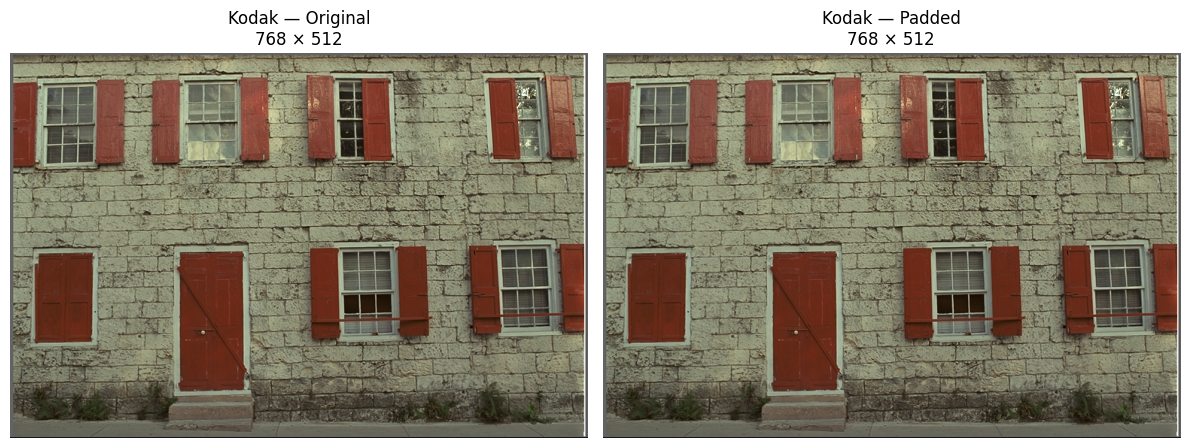

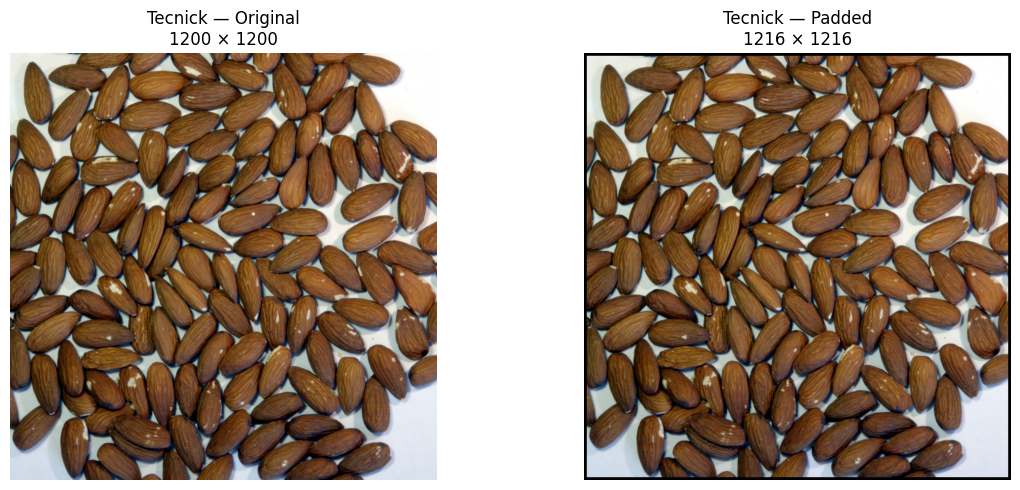

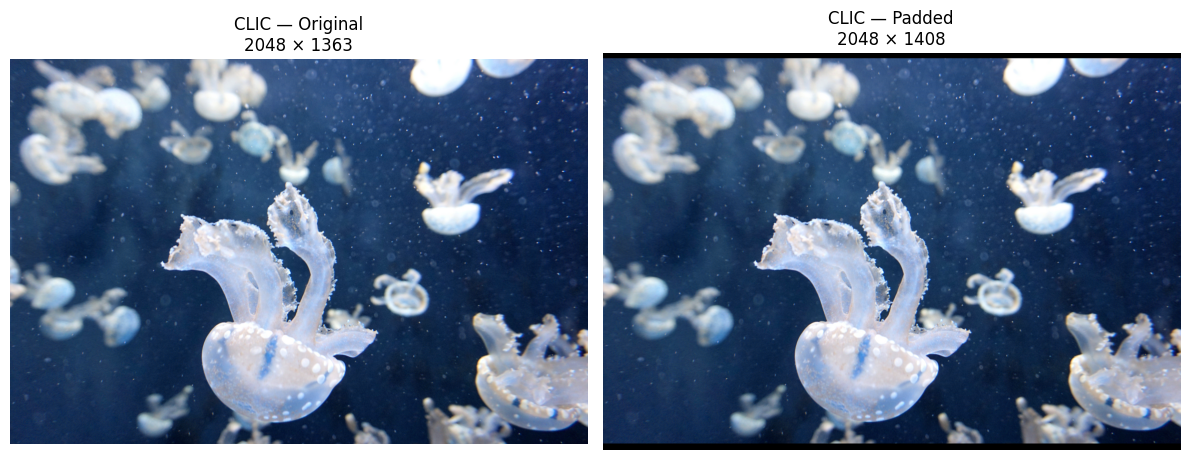

In [ ]:
# ============================================================
# 3.5 — VISUALIZE ORIGINAL AND PADDED IMAGES
# ============================================================

from torchvision.transforms.functional import to_pil_image

for dataset_name in sample_images.keys():

    original_image = sample_images[dataset_name]

    padded_tensor = padded_tensors[dataset_name]

    # Convert padded tensor back to PIL for visualization
    padded_image = to_pil_image(
        padded_tensor.squeeze(0).cpu()
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 5)
    )

    # Original image
    axes[0].imshow(original_image)

    axes[0].set_title(
        f"{dataset_name} — Original\n"
        f"{original_image.width} × {original_image.height}"
    )

    axes[0].axis("off")

    # Padded image
    axes[1].imshow(padded_image)

    axes[1].set_title(
        f"{dataset_name} — Padded\n"
        f"{padded_image.width} × {padded_image.height}"
    )

    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

## 3.6 — Preprocessing Validation and Tensor Verification

The preprocessing pipeline is validated to ensure that all
images are correctly formatted for neural compression.

The verification checks:

1. Input tensors contain four dimensions.
2. Each image has three RGB channels.
3. Pixel values remain within the range [0, 1].
4. Padded dimensions are divisible by 64.
5. All tensors are located on the selected computing device.
6. The original image content remains unchanged within
   the padded tensor.

These checks help identify preprocessing errors before
running the compression models.

In [ ]:
# ============================================================
# 3.6 — VERIFY PREPROCESSING RESULTS
# ============================================================

for dataset_name, padded in padded_tensors.items():

    original = batch_tensors[dataset_name]
    left, right, top, bottom = padding_info[dataset_name]

    _, channels, height, width = padded.shape

    # Verify tensor dimensions
    assert padded.ndim == 4

    # Verify RGB channels
    assert channels == 3

    # Verify padding dimensions
    assert height % 64 == 0
    assert width % 64 == 0

    # Verify pixel range
    assert padded.min().item() >= 0.0
    assert padded.max().item() <= 1.0

    # Verify device
    assert padded.device == device

    # Recover original region
    original_height = original.shape[-2]
    original_width = original.shape[-1]

    recovered = padded[
        :,
        :,
        top:top + original_height,
        left:left + original_width
    ]

    # Verify original content is preserved
    assert torch.equal(recovered, original)

    print(f"{dataset_name}: All preprocessing checks passed!")

print("\nAll images are ready for AI compression!")

Kodak: All preprocessing checks passed!
Tecnick: All preprocessing checks passed!
CLIC: All preprocessing checks passed!

All images are ready for AI compression!


## 3.7 — Image Preprocessing Summary

This section implemented a standardized preprocessing pipeline
for the selected Kodak, Tecnick, and CLIC benchmark images.

### Completed Operations

1. Converted RGB images into normalized PyTorch tensors.
2. Added batch dimensions for neural network inference.
3. Transferred tensors to the selected CPU or GPU.
4. Applied padding to multiples of 64.
5. Preserved original image dimensions and padding information.
6. Visualized original and padded images.
7. Verified tensor shapes, pixel ranges, and image integrity.

### Output

The preprocessing pipeline produces three dictionaries:

- `batch_tensors`: Original normalized image tensors.
- `padded_tensors`: Padded tensors ready for compression.
- `padding_info`: Padding parameters needed for reconstruction.

These outputs will be used in the next section to perform
actual neural image compression and decompression.



### Next Step

Section 4 will implement the quantitative evaluation framework
for classical and learned image compression methods.

The evaluation framework will include BPP, PSNR, SSIM,
MS-SSIM, and compression/decompression time measurements.

These metrics will subsequently be used to evaluate JPEG
and pretrained CompressAI models under a common protocol.

# Section 4 — Evaluation Metrics and Benchmarking Methodology

## 4.1 — Introduction to Compression Performance Evaluation

Image compression algorithms must be evaluated using standardized
quantitative metrics to ensure fair and reproducible comparisons.

This project evaluates both classical and learned image compression
methods based on three main criteria:

1. **Compression Efficiency**
   - Bits Per Pixel (BPP)
   - Compressed data size

2. **Reconstruction Quality**
   - Peak Signal-to-Noise Ratio (PSNR)
   - Structural Similarity Index (SSIM)
   - Multi-Scale Structural Similarity (MS-SSIM)

3. **Computational Performance**
   - Encoding time
   - Decoding time

### Evaluation Objective

The objective is to establish a reusable evaluation framework
that can assess JPEG, JPEG2000, WebP, AVIF, and pretrained
CompressAI models using the same quantitative metrics.

For Milestone 1, the evaluation functions will be implemented
and validated using preliminary JPEG compression experiments.

The complete comparison between classical and learned codecs
will be performed in subsequent milestones.

## 4.2 — Import Evaluation Libraries

This subsection imports the libraries required to calculate
compression efficiency, image reconstruction quality, and
computational performance.

The evaluation implementation uses:

- PyTorch for numerical operations.
- pytorch-msssim for SSIM and MS-SSIM.
- NumPy for numerical processing.
- Pandas for organizing experimental results.
- Matplotlib for visualization.
- Python's time module for runtime measurements.

In [2]:
%pip install -q pytorch-msssim

In [3]:
# ============================================================
# 4.2 — IMPORT EVALUATION LIBRARIES
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import io

from PIL import Image
from torchvision.transforms.functional import to_tensor
from pytorch_msssim import ssim, ms_ssim

print("=" * 55)
print("EVALUATION ENVIRONMENT")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nEvaluation Metrics:")
print("1. BPP")
print("2. PSNR")
print("3. SSIM")
print("4. MS-SSIM")
print("5. Encoding Time")
print("6. Decoding Time")

print("=" * 55)

EVALUATION ENVIRONMENT
PyTorch: 2.11.0+cpu
NumPy: 2.0.2
Pandas: 2.2.2

Evaluation Metrics:
1. BPP
2. PSNR
3. SSIM
4. MS-SSIM
5. Encoding Time
6. Decoding Time


## 4.3 — Bits Per Pixel (BPP) Calculation

Bits Per Pixel (BPP) measures the average number of compressed
bits required to represent one pixel of the original image.

BPP is calculated as:

BPP = (Compressed Size in Bytes × 8) / (Width × Height)

A lower BPP indicates that fewer bits are used to represent
the image.

However, compression efficiency must always be considered
together with reconstruction quality.

### Important Considerations

- Use the original image dimensions.
- Do not use padded image dimensions.
- Count the actual encoded data.
- Document the bitrate accounting method for each codec.

In [4]:
# ============================================================
# 4.3 — BITS PER PIXEL CALCULATION
# ============================================================

def calculate_bpp(compressed_size_bytes, width, height):
    """
    Calculate bits per pixel (BPP).

    Parameters
    ----------
    compressed_size_bytes : int
        Size of compressed data in bytes.

    width : int
        Original image width.

    height : int
        Original image height.

    Returns
    -------
    float
        Bits per pixel.
    """

    if width <= 0 or height <= 0:
        raise ValueError("Image dimensions must be positive.")

    bpp = (compressed_size_bytes * 8) / (width * height)

    return bpp


# Test
test_bpp = calculate_bpp(
    compressed_size_bytes=50000,
    width=768,
    height=512
)

print(f"Test BPP: {test_bpp:.4f}")

Test BPP: 1.0173


## 4.4 — Peak Signal-to-Noise Ratio (PSNR)

PSNR is a widely used image quality metric that measures
the reconstruction error between an original image and
its compressed-and-reconstructed version.

PSNR is calculated using Mean Squared Error (MSE).

For normalized images with pixel values in [0, 1]:

PSNR = 10 × log10(1 / MSE)

A higher PSNR indicates lower reconstruction error.

PSNR is measured in decibels (dB).

### Evaluation Requirements

- Original and reconstructed images must have identical dimensions.
- Both images must use the same color representation.
- Both images must be normalized to [0, 1].
- Padding must be removed before evaluation.

In [5]:
# ============================================================
# 4.4 — PSNR CALCULATION
# ============================================================

def calculate_psnr(original, reconstructed):
    """
    Calculate PSNR for normalized image tensors.
    """

    if original.shape != reconstructed.shape:
        raise ValueError(
            "Original and reconstructed images "
            "must have identical shapes."
        )

    original = original.float()
    reconstructed = reconstructed.float()

    mse = torch.mean(
        (original - reconstructed) ** 2
    )

    if mse.item() == 0:
        return float("inf")

    psnr = 10 * torch.log10(1.0 / mse)

    return psnr.item()

## 4.5 — Structural Similarity Index (SSIM)

SSIM evaluates the structural similarity between two images.

Unlike PSNR, which measures pixel-wise reconstruction error,
SSIM considers local image characteristics such as:

- Luminance
- Contrast
- Structure

SSIM values generally range from 0 to 1 for typical
image compression evaluations.

Values closer to 1 indicate higher structural similarity.

SSIM provides complementary information to PSNR when
evaluating reconstructed image quality.

In [6]:
# ============================================================
# 4.5 — SSIM CALCULATION
# ============================================================

def calculate_ssim(original, reconstructed):

    if original.shape != reconstructed.shape:
        raise ValueError("Image shapes must match.")

    with torch.no_grad():

        value = ssim(
            original.float(),
            reconstructed.float(),
            data_range=1.0,
            size_average=True
        )

    return value.item()

## 4.6 — Multi-Scale Structural Similarity (MS-SSIM)

MS-SSIM extends the SSIM metric by evaluating structural
similarity at multiple image resolutions.

This allows the metric to capture image quality characteristics
at different spatial scales.

MS-SSIM is commonly used in learned image compression research
because it provides a useful measure of perceptual similarity.

The metric will be used alongside PSNR to evaluate the
rate–distortion performance of classical and learned codecs.

### Interpretation

- Values closer to 1 indicate higher structural similarity.
- Higher MS-SSIM is generally preferred at a fixed bitrate.
- MS-SSIM complements PSNR rather than replacing it.

In [7]:
# ============================================================
# 4.6 — MS-SSIM CALCULATION
# ============================================================

def calculate_ms_ssim(original, reconstructed):

    if original.shape != reconstructed.shape:
        raise ValueError("Image shapes must match.")

    with torch.no_grad():

        value = ms_ssim(
            original.float(),
            reconstructed.float(),
            data_range=1.0,
            size_average=True
        )

    return value.item()

## 4.7 — Unified Image Quality Evaluation Function

A unified evaluation function is implemented to calculate
multiple image quality metrics in a single operation.

The function receives an original image and its reconstructed
version and calculates:

- PSNR
- SSIM
- MS-SSIM

The unified function simplifies experimental evaluation
and ensures that all compression algorithms are assessed
using the same metric implementations.

This function will be reused for classical codecs
and pretrained neural compression models.

In [8]:
# ============================================================
# 4.7 — UNIFIED IMAGE QUALITY EVALUATION
# ============================================================

def evaluate_image_quality(original, reconstructed):
    """
    Evaluate reconstructed image quality.

    Inputs:
        Original and reconstructed image tensors
        with shape (1, 3, H, W).

    Returns:
        Dictionary containing PSNR, SSIM, MS-SSIM.
    """

    if original.shape != reconstructed.shape:
        raise ValueError("Image dimensions do not match.")

    original = original.detach().cpu()
    reconstructed = reconstructed.detach().cpu()

    results = {
        "PSNR": calculate_psnr(
            original,
            reconstructed
        ),

        "SSIM": calculate_ssim(
            original,
            reconstructed
        ),

        "MS-SSIM": calculate_ms_ssim(
            original,
            reconstructed
        )
    }

    return results

## 4.8 — Evaluation Metric Validation

The implemented evaluation functions are validated using
identical original and reconstructed images.

When an image is compared with itself:

- MSE should equal zero.
- PSNR should approach infinity.
- SSIM should equal approximately 1.
- MS-SSIM should equal approximately 1.

This test verifies the basic correctness of the evaluation
implementation before applying it to compressed images.

In [11]:
# ============================================================
# 4.8 — METRIC VALIDATION
# ============================================================

# Use the first available sample image
dataset_name = next(iter(sample_images))

original_image = sample_images[dataset_name]

original_tensor = to_tensor(
    original_image
).unsqueeze(0)

# Identical reconstruction
reconstructed_tensor = original_tensor.clone()

validation_results = evaluate_image_quality(
    original_tensor,
    reconstructed_tensor
)

print("=" * 55)
print("EVALUATION METRIC VALIDATION")
print("=" * 55)

print("Dataset:", dataset_name)

for metric, value in validation_results.items():
    print(f"{metric}: {value:.6f}")

assert np.isinf(validation_results["PSNR"])
assert abs(validation_results["SSIM"] - 1.0) < 1e-5
assert abs(validation_results["MS-SSIM"] - 1.0) < 1e-5

print("\nAll evaluation metrics validated successfully!")

EVALUATION METRIC VALIDATION
Dataset: Kodak
PSNR: inf
SSIM: 1.000000
MS-SSIM: 1.000000

All evaluation metrics validated successfully!


## 4.9 — Evaluation Metrics Summary

This section implemented the quantitative evaluation framework
for Project 30: Rate–Distortion Benchmarking Suite.

### Completed Operations

1. Imported the required evaluation libraries.
2. Implemented Bits Per Pixel (BPP).
3. Implemented Peak Signal-to-Noise Ratio (PSNR).
4. Implemented Structural Similarity Index (SSIM).
5. Implemented Multi-Scale Structural Similarity (MS-SSIM).
6. Developed a unified image quality evaluation function.
7. Validated the evaluation metrics using identical images.

### Output

The following reusable functions are now available:

- `calculate_bpp()`
- `calculate_psnr()`
- `calculate_ssim()`
- `calculate_ms_ssim()`
- `evaluate_image_quality()`

These functions will be used to evaluate compression performance
across different codecs and quality levels.

### Next Step

Section 5 will implement a preliminary JPEG compression
baseline using one image from each benchmark dataset.

JPEG compression will be evaluated at five quality levels:

20, 40, 60, 80, and 95.

The resulting BPP, PSNR, SSIM, and MS-SSIM measurements
will be used to generate preliminary rate–distortion curves.